In [ ]:
#56k data
#  1. IMPORTS
# ==============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23420\1615901507.py:3: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
# 2. LOAD DATA
# ==============================
df = pd.read_csv("../delhi-aqi-prediction-using-ml/data/delhi_unprocessed.csv")

# Convert datetime
df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

# Sort (important for time series)
df = df.sort_values("datetime")

In [3]:
# 3. SELECT FEATURES
# ==============================
features = ["pm25", "pm10", "no2", "so2", "co", "o3"]

X = df[features]
y = df["aqi"]

In [4]:
# 4. TIME-BASED SPLIT 
# ==============================
train = df[df["datetime"] < "2022-01-01"]
test = df[df["datetime"] >= "2022-01-01"]

X_train = train[features]
y_train = train["aqi"]

X_test = test[features]
y_test = test["aqi"]

In [5]:
# 5. LINEAR REGRESSION
# ==============================
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [6]:
# 6. RANDOM FOREST
# ==============================
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [7]:
# 7. SVR (WITH SCALING)
# ==============================
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svr.fit(X_train_scaled, y_train)

y_pred_svr = svr.predict(X_test_scaled)


In [8]:
# 8. EVALUATION FUNCTION
# ==============================
def evaluate(y_true, y_pred):
    return [
        r2_score(y_true, y_pred),
        mean_absolute_error(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred))
    ]


Model Comparison Table:

            Model  R2 Score   MAE   RMSE
    Random Forest      1.00  3.79   6.69
              SVR      0.99  9.15  13.47
Linear Regression      0.53 81.92 116.13

Feature Importance:

pm25    0.689959
pm10    0.079441
co      0.068421
o3      0.064441
no2     0.051438
so2     0.046299
dtype: float64


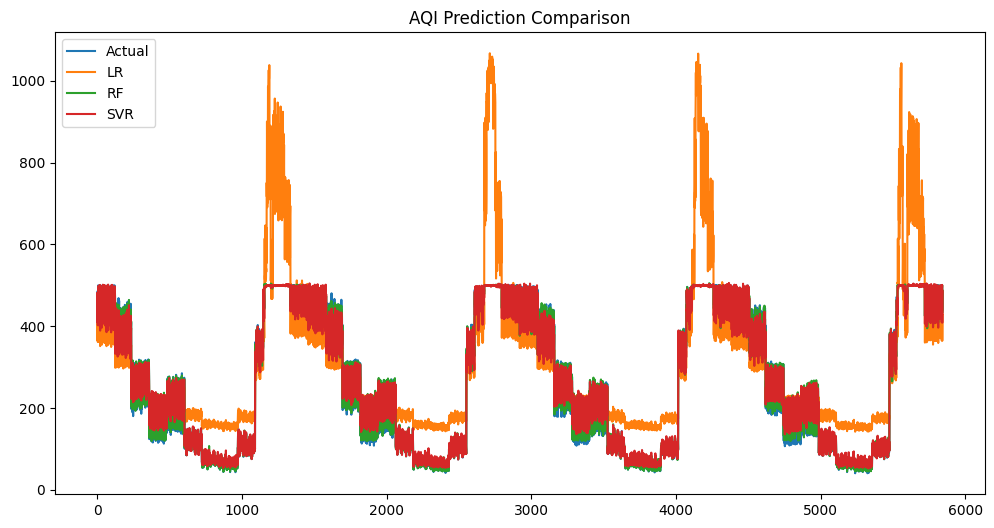

In [9]:
# 9. MODEL COMPARISON TABLE
# ==============================
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "SVR"],
    "R2 Score": [
        evaluate(y_test, y_pred_lr)[0],
        evaluate(y_test, y_pred_rf)[0],
        evaluate(y_test, y_pred_svr)[0]
    ],
    "MAE": [
        evaluate(y_test, y_pred_lr)[1],
        evaluate(y_test, y_pred_rf)[1],
        evaluate(y_test, y_pred_svr)[1]
    ],
    "RMSE": [
        evaluate(y_test, y_pred_lr)[2],
        evaluate(y_test, y_pred_rf)[2],
        evaluate(y_test, y_pred_svr)[2]
    ]
})

# Clean display
results = results.round(2)
results = results.sort_values(by="R2 Score", ascending=False)

print("\nModel Comparison Table:\n")
print(results.to_string(index=False))


# ==============================
# 10. FEATURE IMPORTANCE (RF)
# ==============================
feat_imp = pd.Series(rf.feature_importances_, index=features)
print("\nFeature Importance:\n")
print(feat_imp.sort_values(ascending=False))


# ==============================
# 11. PLOT (ACTUAL VS PREDICTED)
# ==============================
plt.figure(figsize=(12,6))

plt.plot(y_test.values, label="Actual")
plt.plot(y_pred_lr, label="LR")
plt.plot(y_pred_rf, label="RF")
plt.plot(y_pred_svr, label="SVR")

plt.legend()
plt.title("AQI Prediction Comparison")
plt.show()